In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
n_rows = 4
n_cols = 4
n_states = n_rows * n_cols
n_actions = 4
transitions = np.zeros((n_states, n_actions, n_states))
rewards = np.zeros((n_states, n_actions, n_states))
gamma = 0.9

for row in range(n_rows):
    for col in range(n_cols):
        s = row * n_cols + col
        for a in range(n_actions):
            if a == 0:
                #move up
                s1 = max(row-1, 0) * n_cols + col
            elif a == 1:
                #move down
                s1 = min(row+1, n_rows-1) * n_cols + col
            elif a == 2:
                #move left
                s1 = row * n_cols + max(col-1, 0)
            else:
                #move right
                s1 = row * n_cols + min(col+1, n_cols-1)

            transitions[s, a, s1] = 1.0
            rewards[s, a, s1] = -1 if s1 != n_states-1 else 0.0

In [3]:
def value_iteration(transitions, rewards, gamma, n_states, n_actions):
    v = np.zeros(n_states)
    v_history = [v.copy()]
    delta = 1

    #value iteration
    while delta > 1e-6:
        delta = 0

        for s in range(n_states):
            v_old = v[s]
            q = np.zeros(n_actions)

            for a in range(n_actions):
                q[a] = sum(transitions[s, a, s1] * (rewards[s, a, s1] + gamma * v[s1]) for s1 in range(n_states))
            
            v[s] = np.max(q)
            delta = max(delta, abs(v_old - v[s]))
        v_history.append(v.copy())

    #deriving policy
    policy = np.zeros(n_states, dtype=int)
    for s in range(n_states):
        q = np.zeros(n_actions)
        for a in range(n_actions):
            q[a] = sum(transitions[s, a, s1] * (rewards[s, a, s1] + gamma * v[s1]) for s1 in range(n_states))
        policy[s] = np.argmax(q)
    return policy, v, v_history

In [4]:
policy, v, v_history = value_iteration(transitions, rewards, gamma, n_states, n_actions)

#policy convergence graph

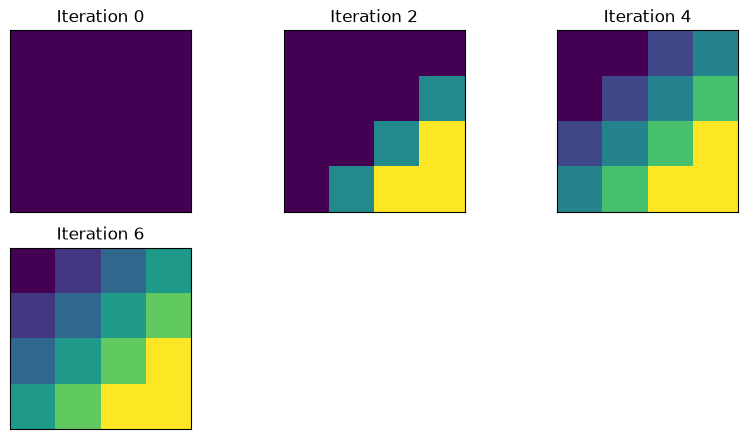

In [5]:
plt.figure(figsize=(10, 8))

for i in range(0, len(v_history), 2):
    plt.subplot(3, 3, int(i/2+1))
    plt.imshow(v_history[i].reshape(n_rows, n_cols))
    plt.title('Iteration {}'.format(i))
    plt.xticks([])
    plt.yticks([])

plt.show()

#optimal actions graph

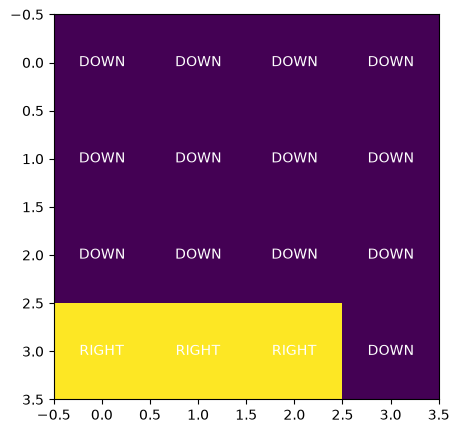

In [6]:
actions = ['UP', 'DOWN', 'LEFT', 'RIGHT']

plt.figure(figsize=(6, 5))
plt.imshow(policy.reshape(n_rows, n_cols))

for row in range(n_rows):
    for col in range(n_cols):
        plt.text(col, row, actions[policy[row * n_cols + col]],
                 color = 'white', ha = 'center', va = 'center')

plt.show()